# Investigating specificity information in AF3 Scores

In this notebook, we investigate the ability of alphafold3 confidence scores at discriminating between binding and non-binding TCR:pMHC complexes.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import ranksums
from sklearn.metrics import roc_auc_score

In [2]:
af3_scores = pd.read_csv('../data/processed/af3_confidence_scores.csv')
af3_scores['structure_name'] = af3_scores['structure_name'].astype('str')

In [3]:
sequences = pd.read_csv('../data/interim/sequences_sample.csv', index_col='index')
sequences.index = sequences.index.astype('str')

In [4]:
af3_scores = af3_scores.merge(sequences, left_on='structure_name', right_index=True, how='left')

In [5]:
af3_scores['type'] = af3_scores['label'].map(lambda label: 'binder' if label else 'decoy')

In [8]:
[col for col in af3_scores.columns if 'ptm' not in col and 'pae' not in col]

['structure_name',
 'seed',
 'sample',
 'fraction_disordered',
 'has_clash',
 'ranking_score',
 'top_model',
 'tcr_pmhc_plddt_score',
 'cdr_pmhc_plddt_score',
 'cdr1_alpha',
 'cdr2_alpha',
 'cdr3_alpha',
 'cdr1_beta',
 'cdr2_beta',
 'cdr3_beta',
 'peptide',
 'mhc_pseudo',
 'v_alpha',
 'j_alpha',
 'v_beta',
 'j_beta',
 'mhc1',
 'mhc2',
 'mhc_type',
 'species',
 'source',
 'label',
 'fold',
 'type']

In [9]:
scores_summary = []

for column_name in af3_scores.filter(regex=r'ptm').columns:
    score_summary = {
        'metric': column_name,
    }

    # All Models
    roc = roc_auc_score(af3_scores['label'], af3_scores[column_name])
    stat, p_val = ranksums(
        af3_scores.query("type == 'binder'")[column_name],
        af3_scores.query("type == 'decoy'")[column_name],
        alternative='greater',
    )
    score_summary['roc_all_models'] = roc
    score_summary['stat_all_models'] = stat
    score_summary['p_val_all_models'] = p_val

    # Top Model
    roc = roc_auc_score(af3_scores.query('top_model')['label'], af3_scores.query('top_model')[column_name])
    stat, p_val = ranksums(
        af3_scores.query("top_model and type == 'binder'")[column_name],
        af3_scores.query("top_model and type == 'decoy'")[column_name],
        alternative='greater',
    )
    score_summary['roc_top_model'] = roc
    score_summary['stat_top_model'] = stat
    score_summary['p_val_top_model'] = p_val

    scores_summary.append(score_summary)

for column_name in af3_scores.filter(regex=r'pae').columns:
    score_summary = {
        'metric': column_name,
    }

    # All Models
    roc = 1 - roc_auc_score(af3_scores['label'], af3_scores[column_name])
    stat, p_val = ranksums(
        af3_scores.query("type == 'binder'")[column_name],
        af3_scores.query("type == 'decoy'")[column_name],
        alternative='less',
    )
    score_summary['roc_all_models'] = roc
    score_summary['stat_all_models'] = stat
    score_summary['p_val_all_models'] = p_val

    # Top Model
    roc = 1 - roc_auc_score(af3_scores.query('top_model')['label'], af3_scores.query('top_model')[column_name])
    stat, p_val = ranksums(
        af3_scores.query("top_model and type == 'binder'")[column_name],
        af3_scores.query("top_model and type == 'decoy'")[column_name],
        alternative='less',
    )
    score_summary['roc_top_model'] = roc
    score_summary['stat_top_model'] = stat
    score_summary['p_val_top_model'] = p_val

    scores_summary.append(score_summary)

for column_name in af3_scores.filter(regex=r'plddt').columns:
    score_summary = {
        'metric': column_name,
    }

    # All Models
    roc = roc_auc_score(af3_scores['label'], af3_scores[column_name])
    stat, p_val = ranksums(
        af3_scores.query("type == 'binder'")[column_name],
        af3_scores.query("type == 'decoy'")[column_name],
        alternative='greater',
    )
    score_summary['roc_all_models'] = roc
    score_summary['stat_all_models'] = stat
    score_summary['p_val_all_models'] = p_val

    # Top Model
    roc = roc_auc_score(af3_scores.query('top_model')['label'], af3_scores.query('top_model')[column_name])
    stat, p_val = ranksums(
        af3_scores.query("top_model and type == 'binder'")[column_name],
        af3_scores.query("top_model and type == 'decoy'")[column_name],
        alternative='greater',
    )
    score_summary['roc_top_model'] = roc
    score_summary['stat_top_model'] = stat
    score_summary['p_val_top_model'] = p_val

    scores_summary.append(score_summary)

scores_summary = pd.DataFrame(scores_summary)
scores_summary = scores_summary.set_index('metric')

In [10]:
scores_summary.sort_values('roc_all_models', ascending=False)

,roc_all_models,stat_all_models,p_val_all_models,roc_top_model,stat_top_model,p_val_top_model
metric,,,,,,
tcr_pmhc_pae_score,0.669824,-4.641548,0.000002,0.6816,-2.202223,0.013825
mhc_chain_2_iptm,0.669760,4.639799,0.000002,0.6784,2.163418,0.015255
beta_chain_mhc_chain_1_pae_min,0.669728,-4.638924,0.000002,0.6752,-2.124612,0.016809
beta_chain_mhc_chain_2_pae_min,0.667680,-4.582949,0.000002,0.6816,-2.202223,0.013825
beta_chain_antigen_chain_pae_min,0.665312,-4.518228,0.000003,0.6696,-2.056702,0.019857
mhc_chain_2_beta_chain_iptm,0.665120,4.512980,0.000003,0.6776,2.153716,0.015631
cdr_pmhc_plddt_score,0.664256,4.489366,0.000004,0.6800,2.182821,0.014525
iptm,0.664000,4.482369,0.000004,0.6744,2.114911,0.017219
beta_chain_iptm,0.663264,4.462253,0.000004,0.6712,2.076105,0.018942


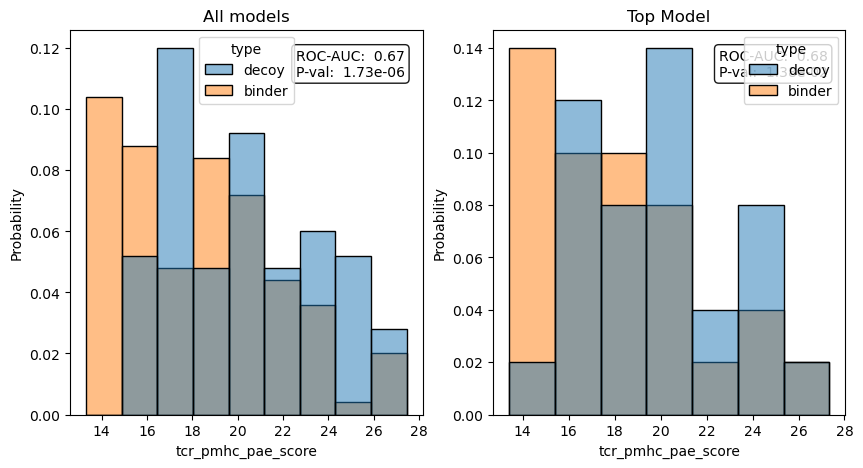

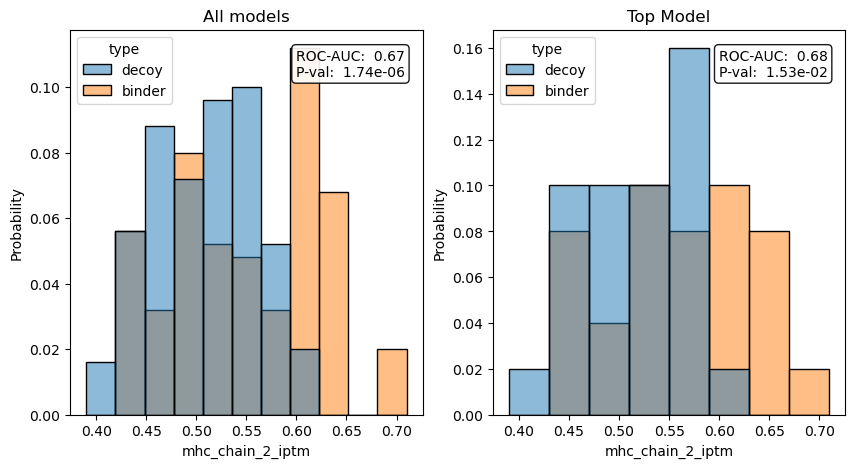

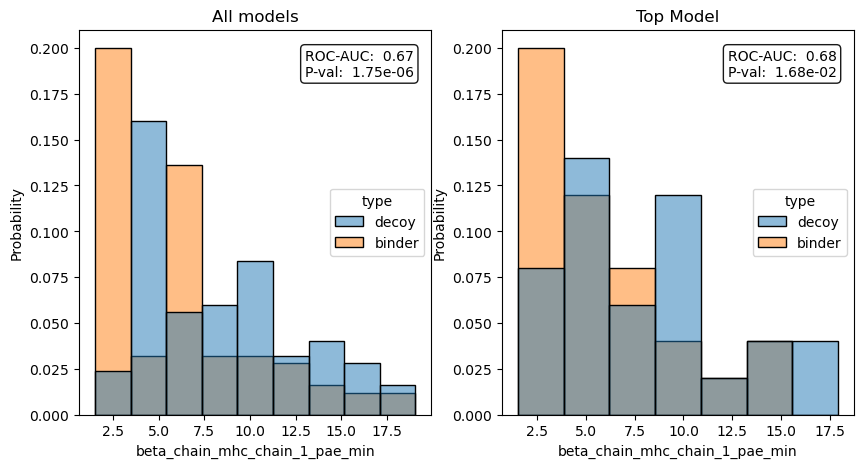

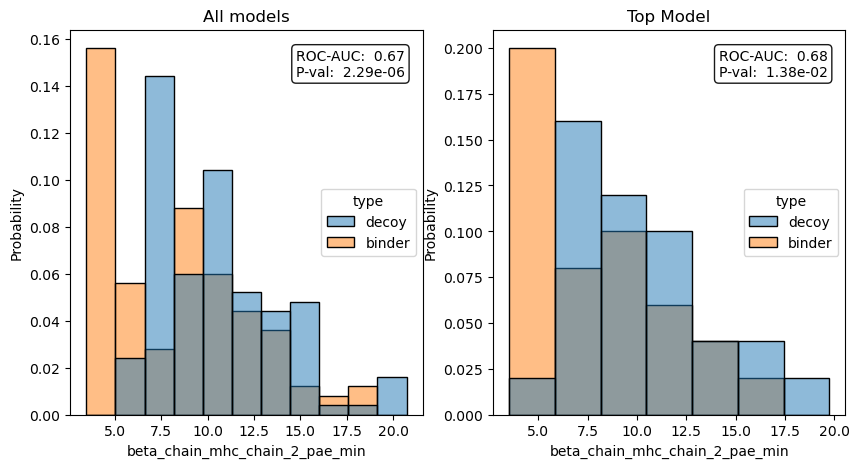

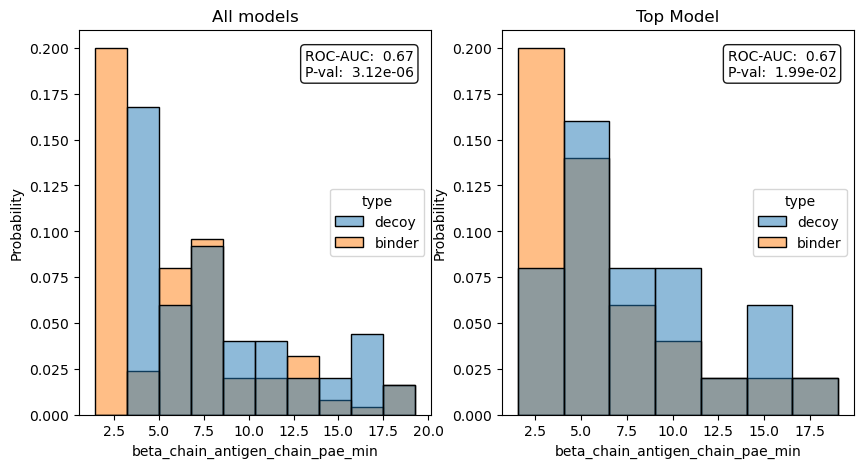

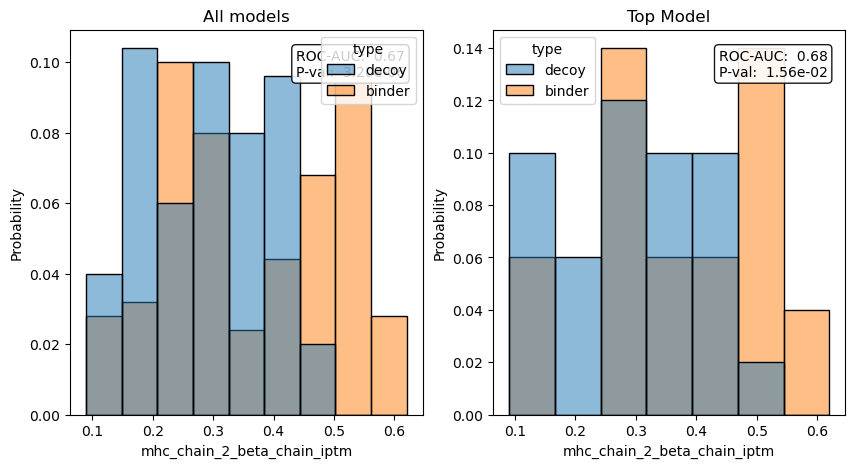

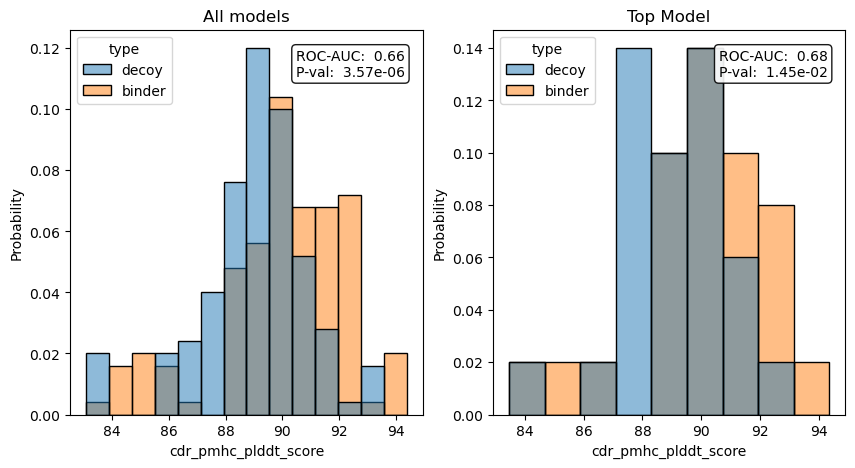

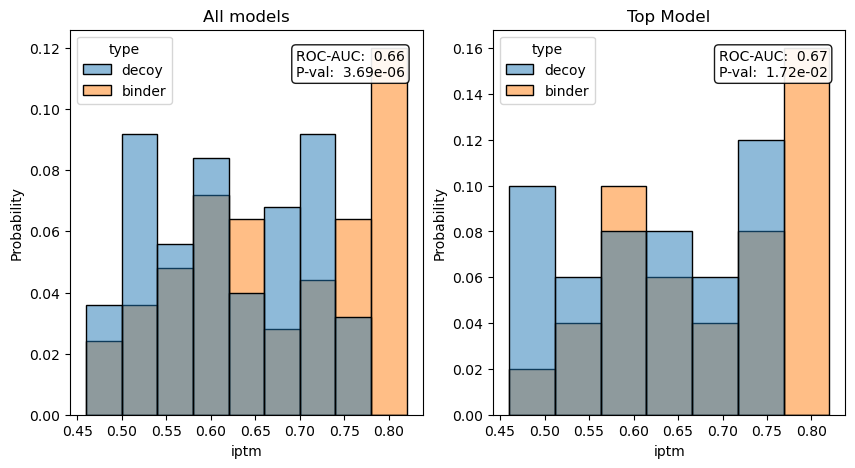

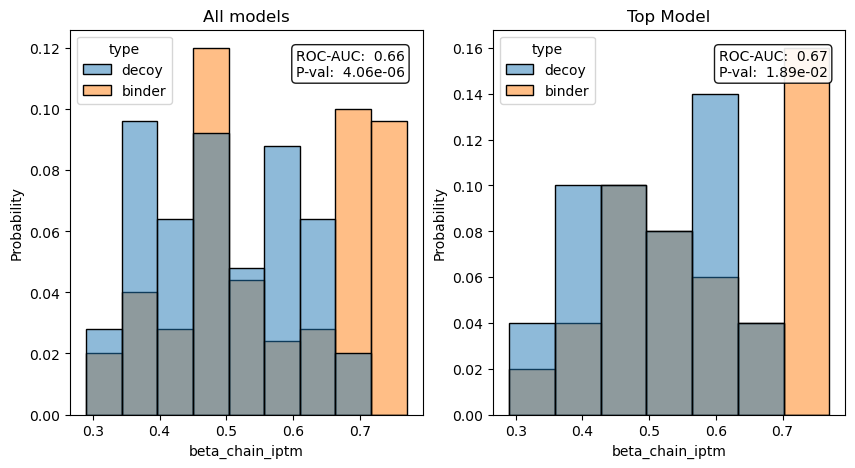

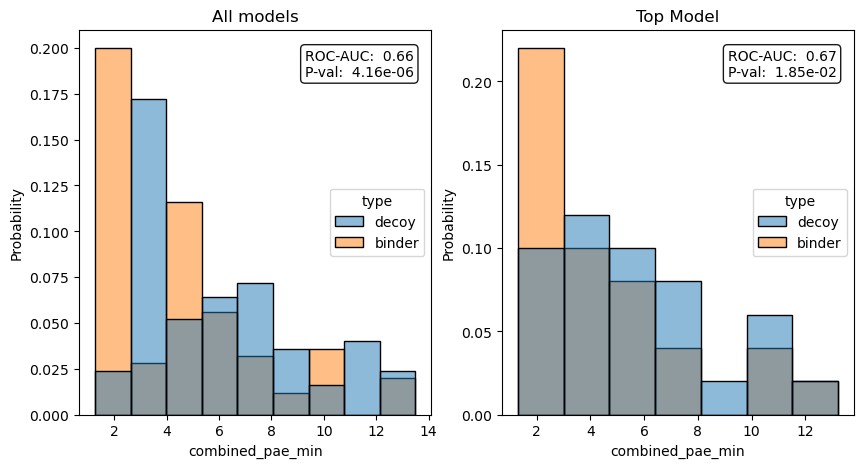

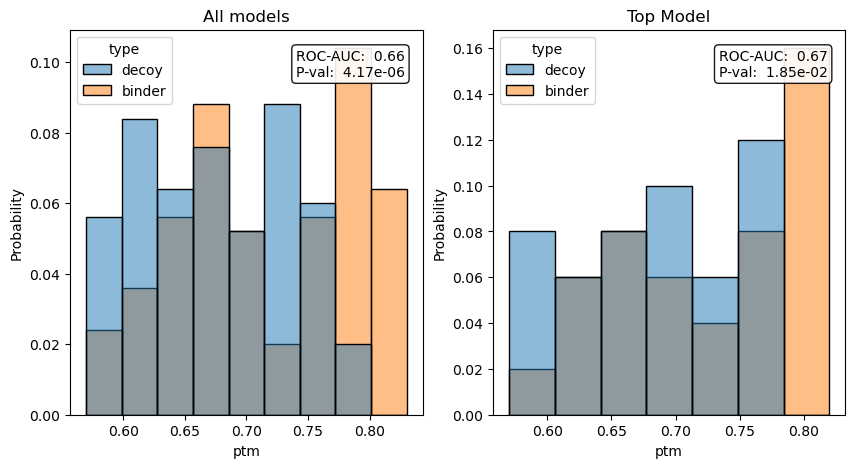

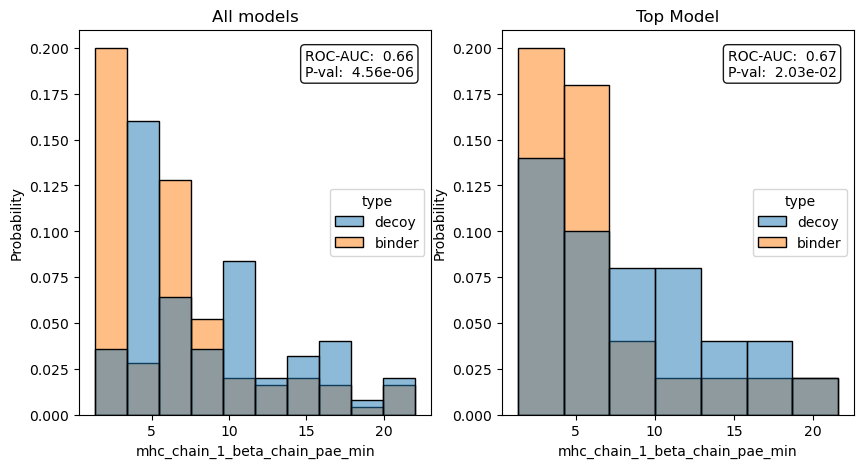

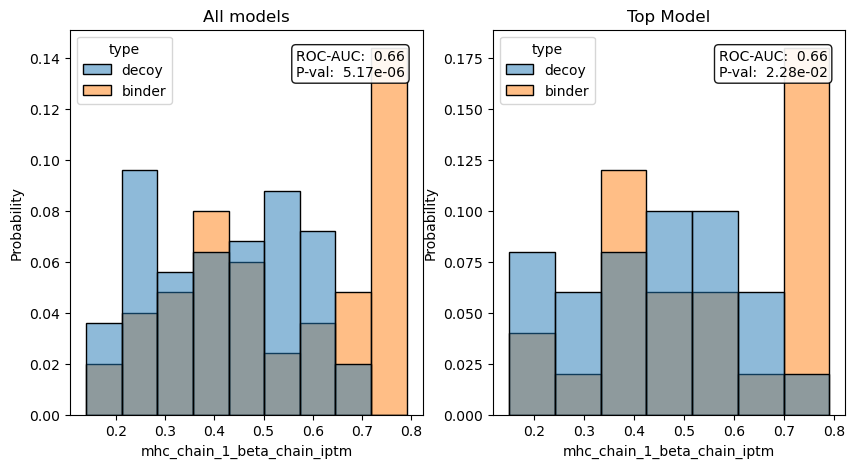

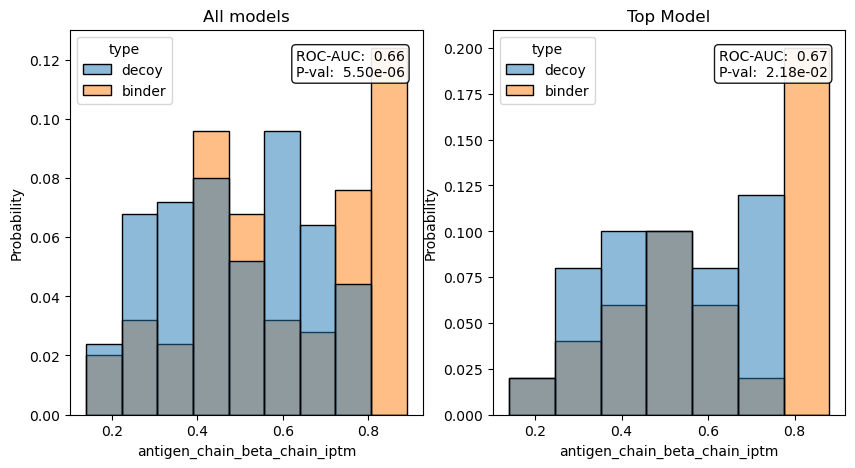

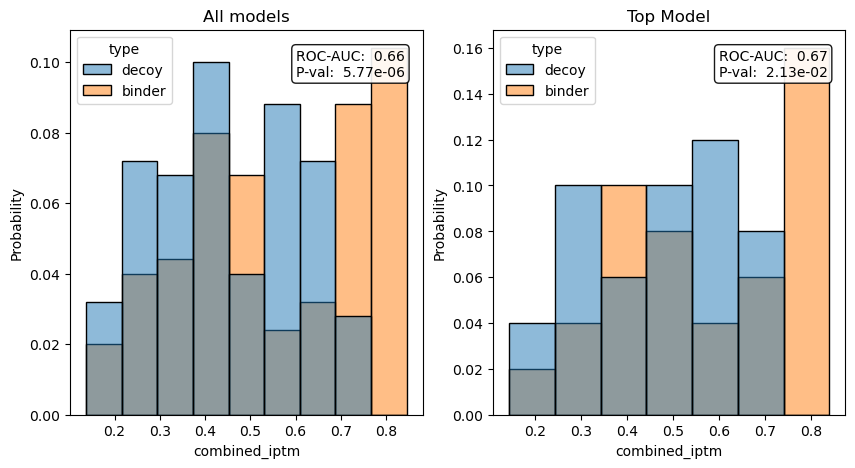

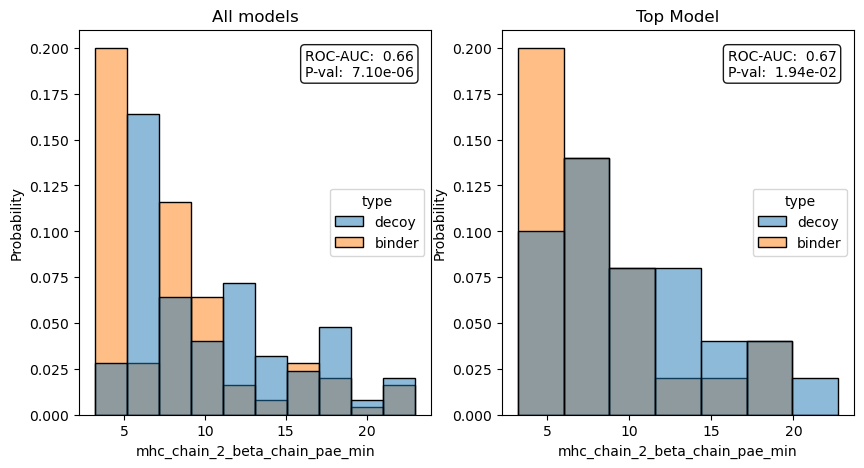

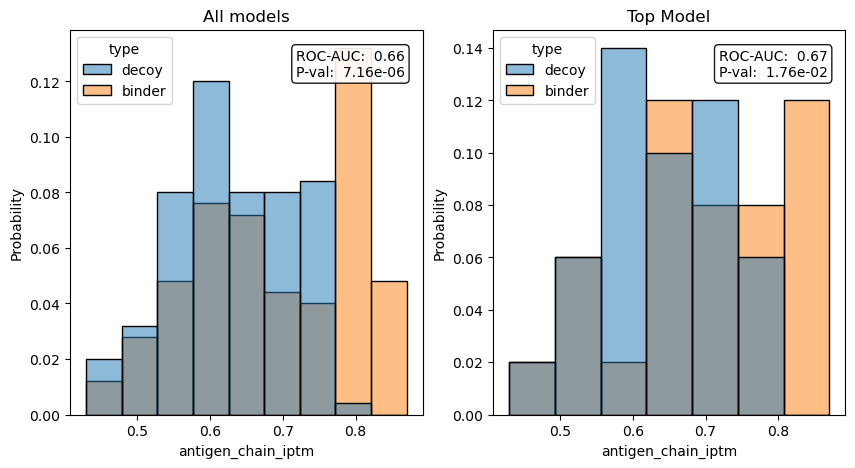

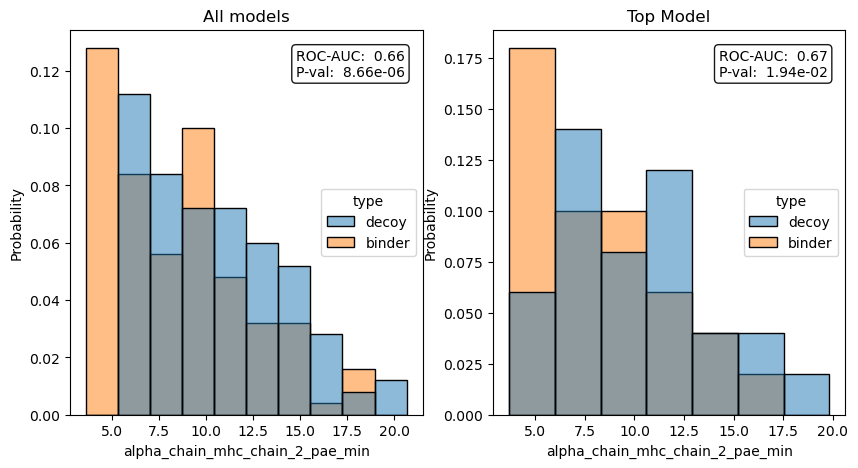

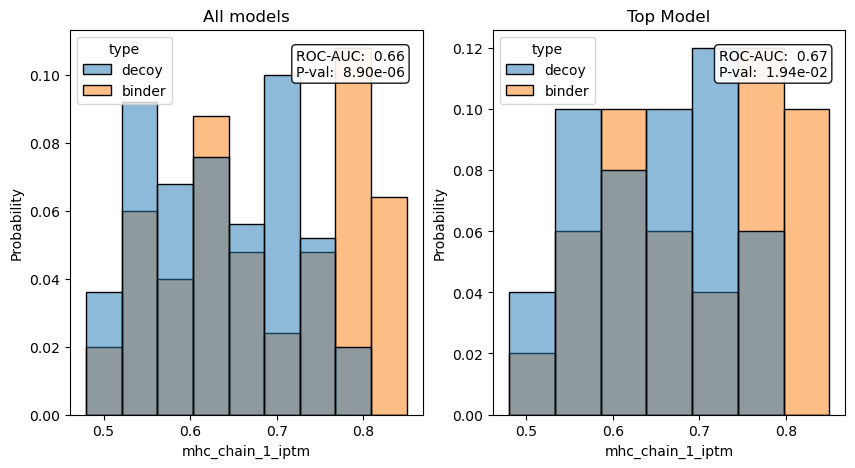

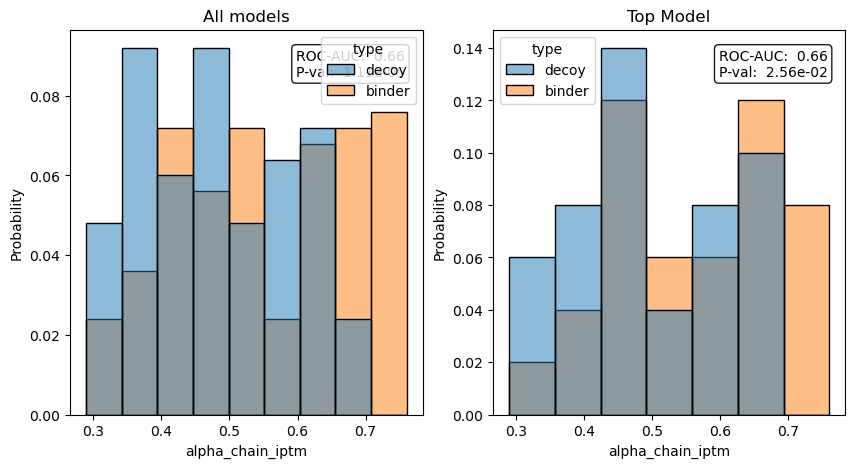

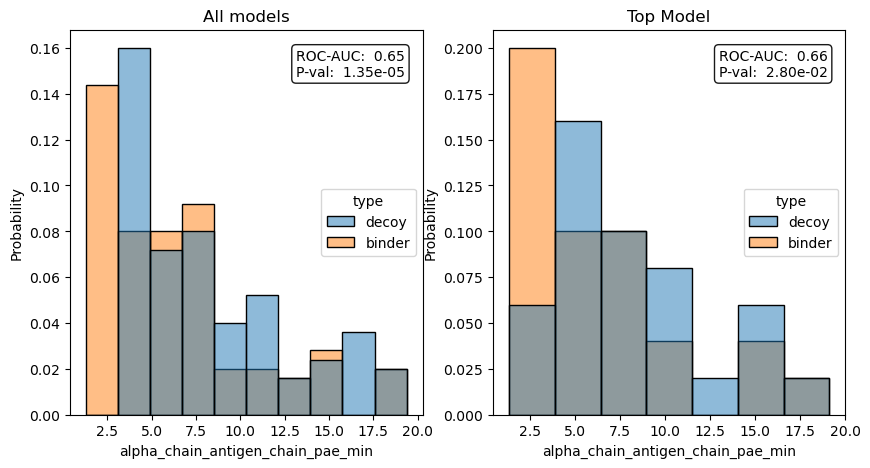

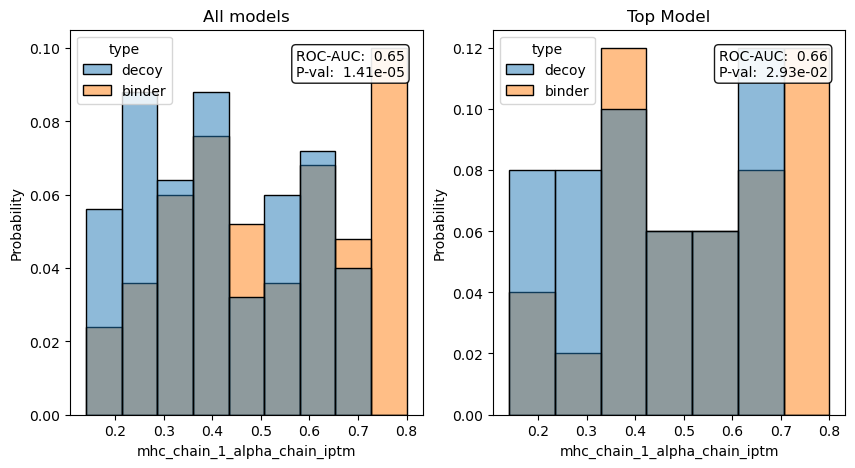

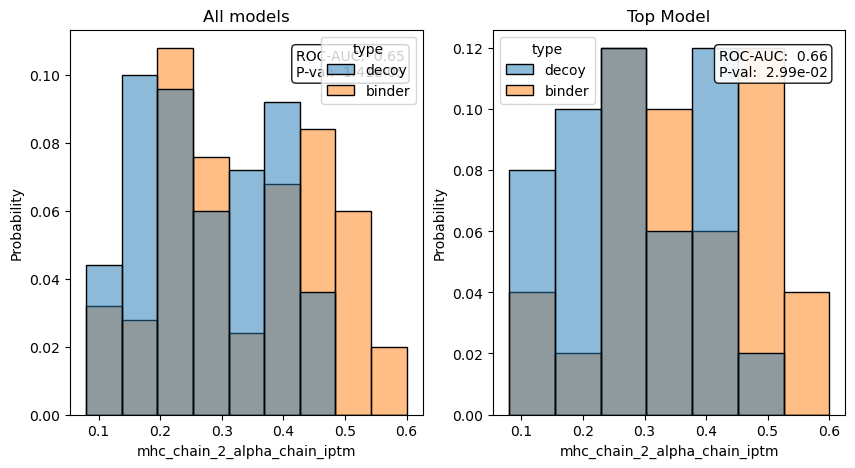

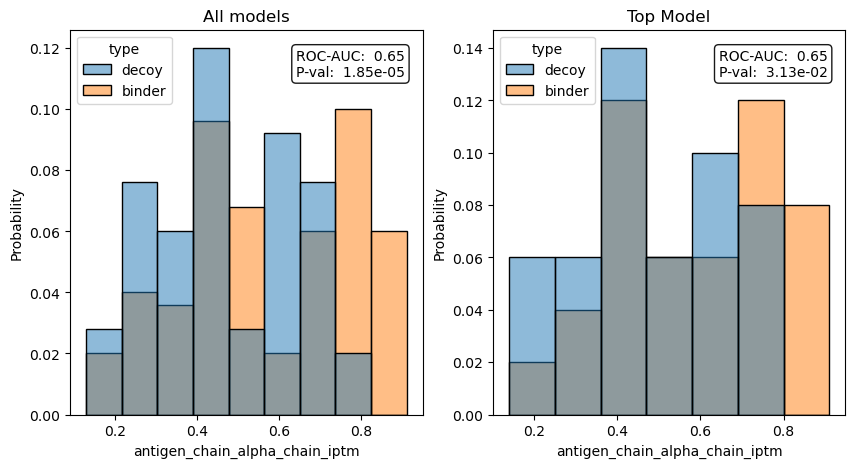

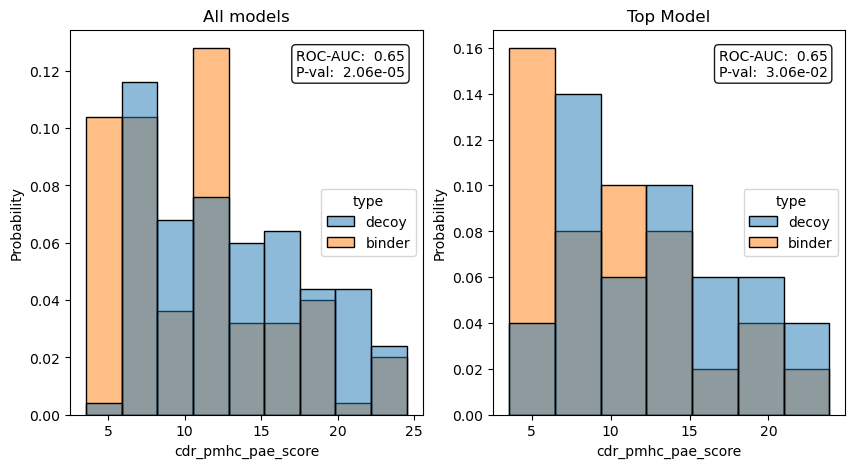

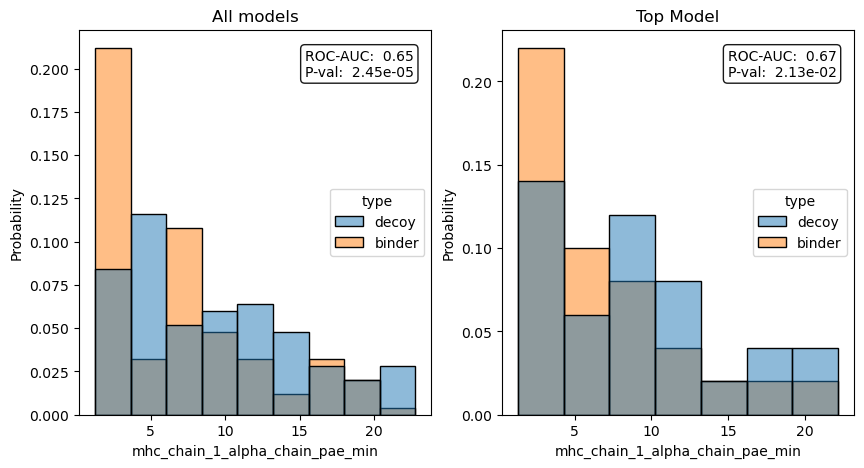

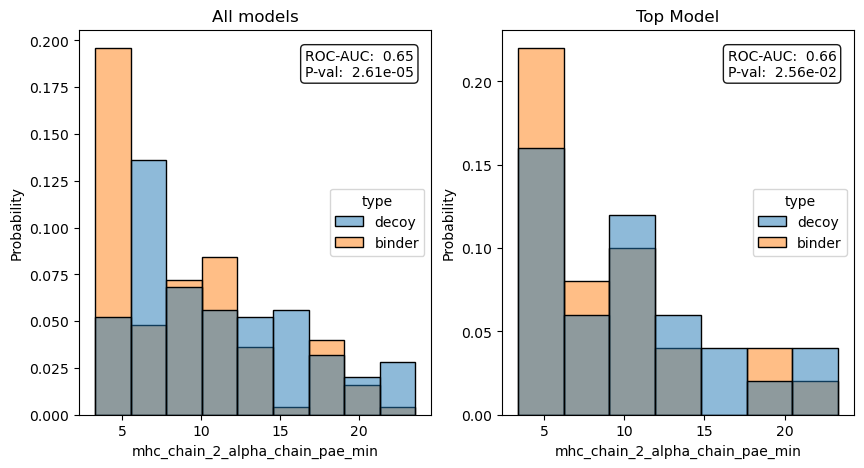

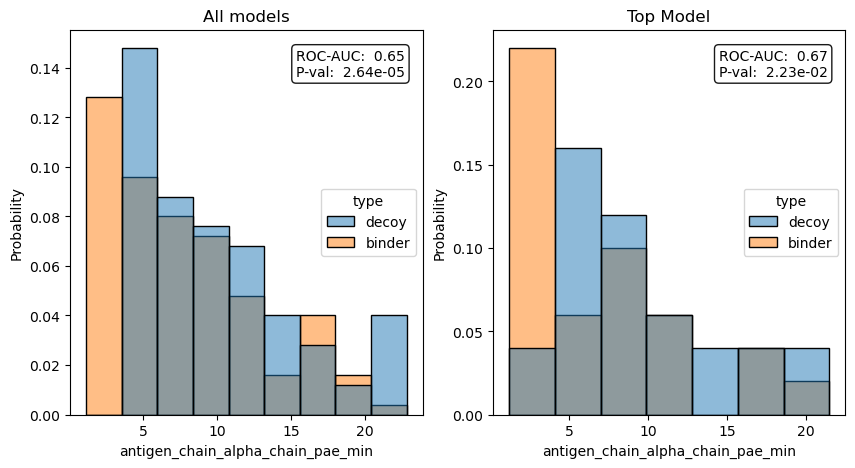

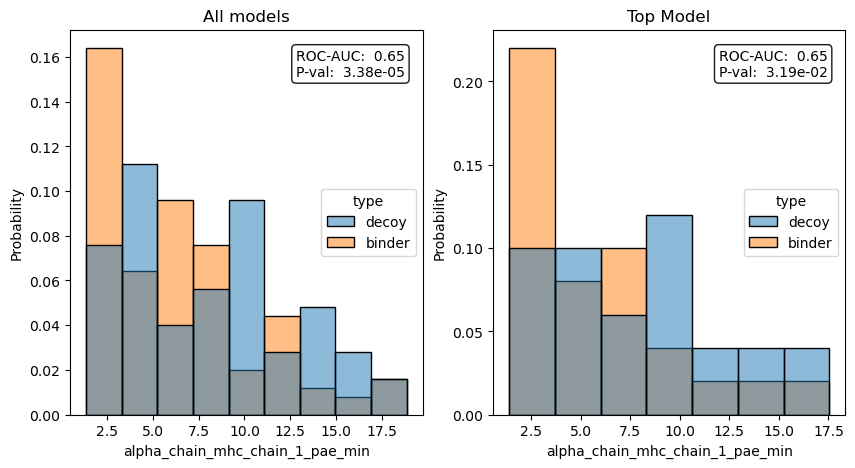

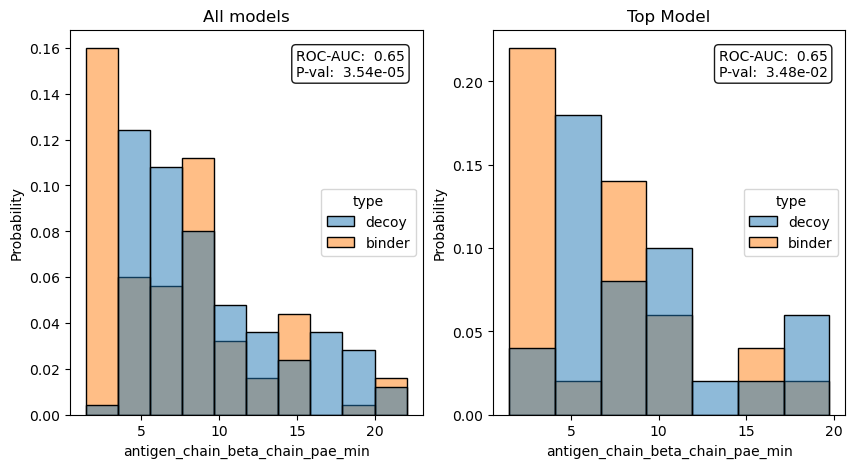

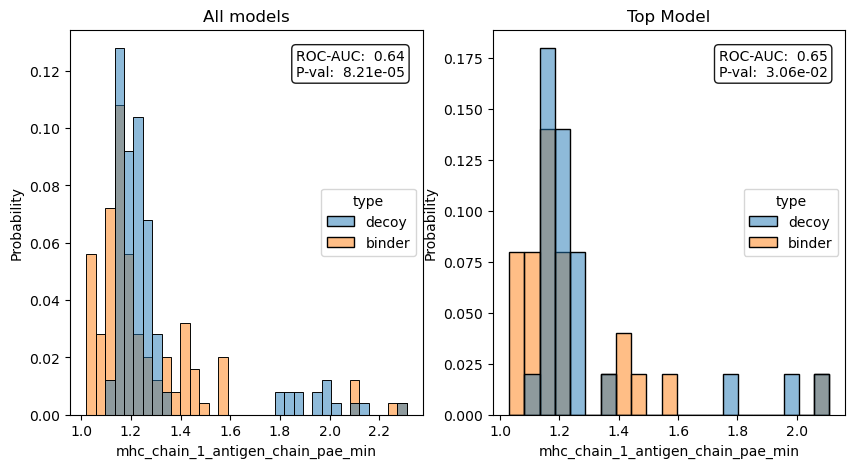

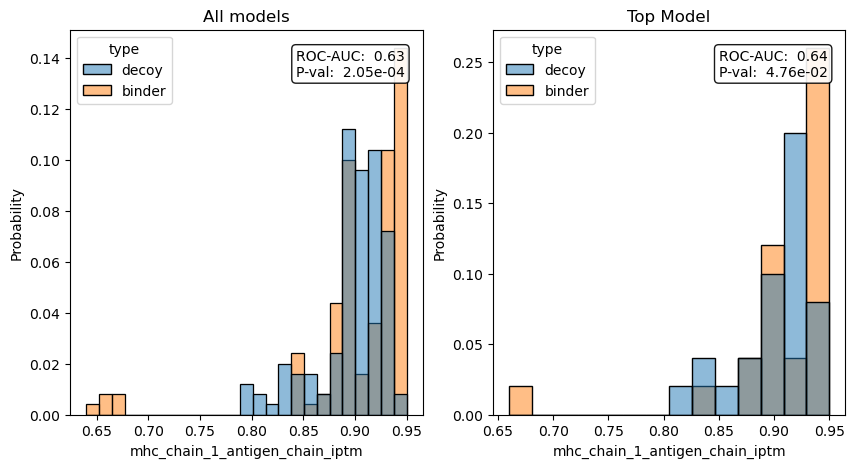

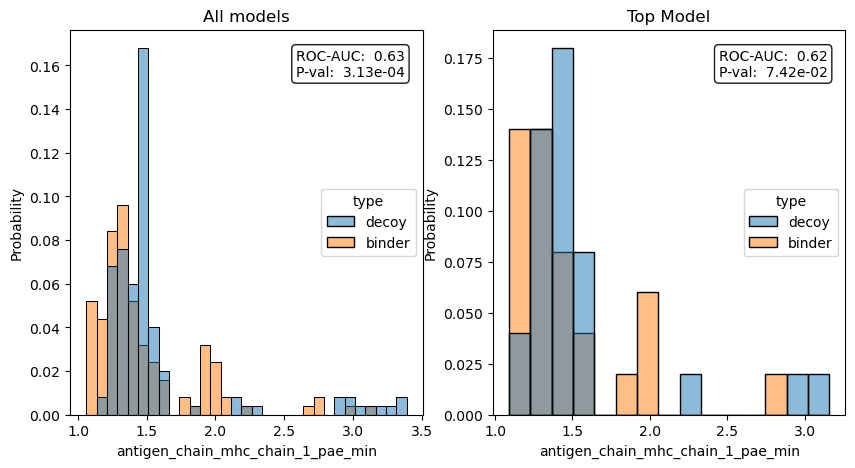

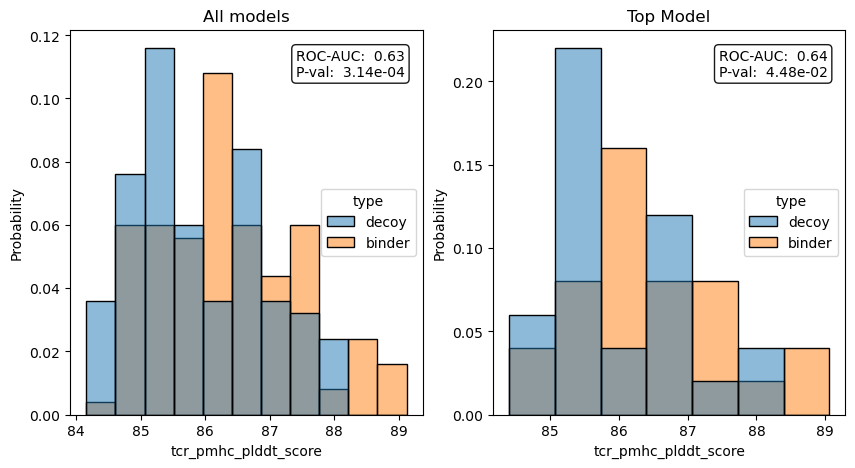

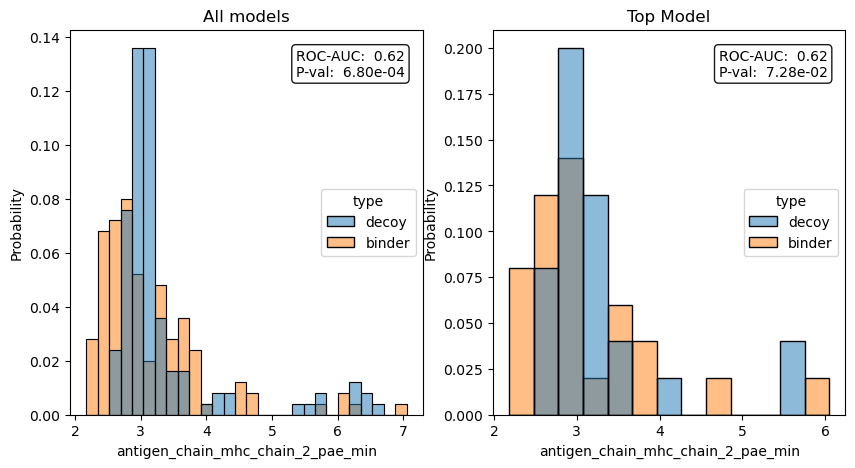

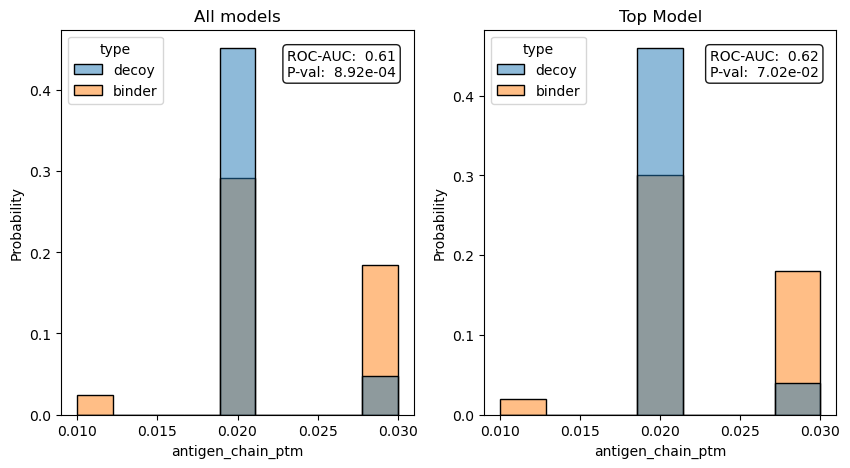

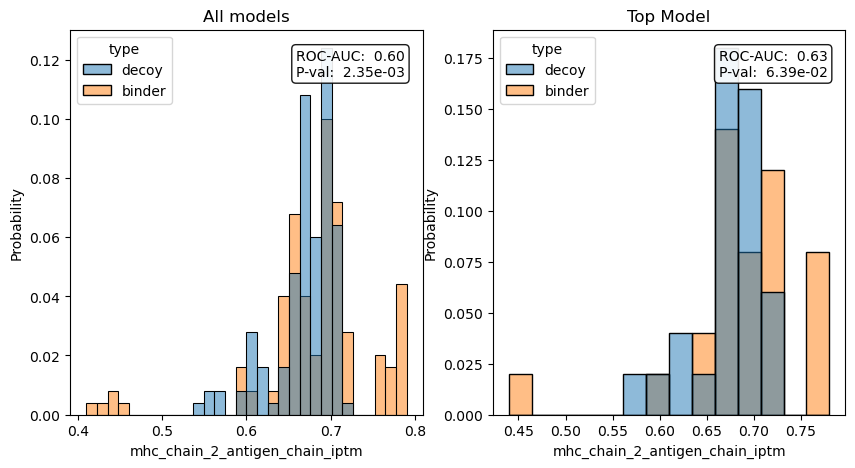

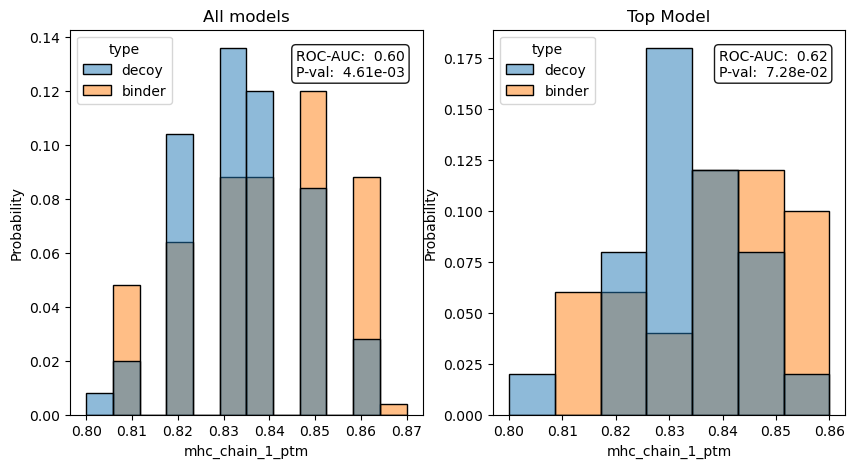

In [11]:
for column_name, row in (
    scores_summary.sort_values('roc_all_models', ascending=False).query('p_val_all_models < 0.05').iterrows()
):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

    # All Models
    sns.histplot(af3_scores, x=column_name, hue='type', stat='probability', ax=ax1)
    ax1.set_title('All models')
    ax1.text(
        0.95,
        0.95,
        f"ROC-AUC: {row['roc_all_models']: .2f}\nP-val: {row['p_val_all_models']: .2e}",
        transform=ax1.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
    )

    # Top Model
    sns.histplot(af3_scores.query('top_model'), x=column_name, hue='type', stat='probability', ax=ax2)
    ax2.text(
        0.95,
        0.95,
        f"ROC-AUC: {row['roc_top_model']: .2f}\nP-val: {row['p_val_top_model']: .2e}",
        transform=ax2.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
    )
    ax2.set_title('Top Model')

    plt.show()